# Understanding PDB Files

PDB (Protein Data Bank) files contain 3D structural data of proteins and nucleic acids. They typically have been collected from experimental techniques such as X-ray crystallography, NMR spectroscopy, and cryo-electron microscopy. They can be explored on the RCSB PDB website (https://www.rcsb.org/).

The data contained within PDB files are what have enabled models like AlphaFold to exist in the first place, thus I think they are worth exploring in a bit more detail.

In this notebook I will begin to explore what is actually contained within PDB files and how we can access this data programmatically.

## Reading a PDB File in Python directly

PDB files use a file extension of `.pdb`, I have included an example file named `1UBQ.pdb` which contains the structural data for the protein ubiquitin.

Let's read the contents of this file to begin exploring the structural data it contains.

In [50]:
with open("1UBQ.pdb", "r") as f:
    pdb_data = f.read()

print(pdb_data[:1000])

HEADER    CHROMOSOMAL PROTEIN                     02-JAN-87   1UBQ              
TITLE     STRUCTURE OF UBIQUITIN REFINED AT 1.8 ANGSTROMS RESOLUTION            
COMPND    MOL_ID: 1;                                                            
COMPND   2 MOLECULE: UBIQUITIN;                                                 
COMPND   3 CHAIN: A;                                                            
COMPND   4 ENGINEERED: YES                                                      
SOURCE    MOL_ID: 1;                                                            
SOURCE   2 ORGANISM_SCIENTIFIC: HOMO SAPIENS;                                   
SOURCE   3 ORGANISM_COMMON: HUMAN;                                              
SOURCE   4 ORGANISM_TAXID: 9606                                                 
KEYWDS    CHROMOSOMAL PROTEIN                                                   
EXPDTA    X-RAY DIFFRACTION                                                     
AUTHOR    S.VIJAY-KUMAR,C.E.

We can see that the header of the file gives us quite a bit of information about what it contains; the protein name, the organism it comes from (human in this case), the date which it was deposited, the experimental method used to determine the structure, it's PDB code and the author who submitted the structure.

### How are sequence and structure represented in PDB files?

PDB files contain both the amino acid sequence and the three-dimensional structure of a protein.

The sequence is contained within lines that begin with the keyword `SEQRES`. We can print these lines as follows:

In [51]:
for pdb_line in pdb_data.splitlines():
    if pdb_line.startswith("SEQRES"):
        print(pdb_line)

SEQRES   1 A   76  MET GLN ILE PHE VAL LYS THR LEU THR GLY LYS THR ILE          
SEQRES   2 A   76  THR LEU GLU VAL GLU PRO SER ASP THR ILE GLU ASN VAL          
SEQRES   3 A   76  LYS ALA LYS ILE GLN ASP LYS GLU GLY ILE PRO PRO ASP          
SEQRES   4 A   76  GLN GLN ARG LEU ILE PHE ALA GLY LYS GLN LEU GLU ASP          
SEQRES   5 A   76  GLY ARG THR LEU SER ASP TYR ASN ILE GLN LYS GLU SER          
SEQRES   6 A   76  THR LEU HIS LEU VAL LEU ARG LEU ARG GLY GLY                  


Here we can see the amino sequence represented in 6 lines of the file. The lines being by telling us how many chains are present (here just one chain: chain A) and listing the total number of resides in that chain (here 76).

What follows are the sequence of amino acids listed in the order they appear in the protein chain. In our case here, the sequence starts with MET (Methionine), GLN (Glutamine) and ILE (Isoleucine).

Lets extract the full sequence and check we get the correct number of amino acids:

In [52]:
aa_sequence = []
for pdb_line in pdb_data.splitlines():
    if pdb_line.startswith("SEQRES"):
        aa_sequence.extend(pdb_line.split()[4:])
assert len(aa_sequence) == 76

So now we have the reported sequence, how do we extract the coordinates that tell us the three-dimensional structure of the protein? In PDB files, these coordinates are contained within lines that begin with the keyword `ATOM`. We can extract these lines and print the first ten rows:

In [53]:
atom_rows = []
for pdb_line in pdb_data.splitlines():
    if pdb_line.startswith("ATOM"):
        atom_rows.append(pdb_line)
atom_rows[:10]

['ATOM      1  N   MET A   1      27.340  24.430   2.614  1.00  9.67           N  ',
 'ATOM      2  CA  MET A   1      26.266  25.413   2.842  1.00 10.38           C  ',
 'ATOM      3  C   MET A   1      26.913  26.639   3.531  1.00  9.62           C  ',
 'ATOM      4  O   MET A   1      27.886  26.463   4.263  1.00  9.62           O  ',
 'ATOM      5  CB  MET A   1      25.112  24.880   3.649  1.00 13.77           C  ',
 'ATOM      6  CG  MET A   1      25.353  24.860   5.134  1.00 16.29           C  ',
 'ATOM      7  SD  MET A   1      23.930  23.959   5.904  1.00 17.17           S  ',
 'ATOM      8  CE  MET A   1      24.447  23.984   7.620  1.00 16.11           C  ',
 'ATOM      9  N   GLN A   2      26.335  27.770   3.258  1.00  9.27           N  ',
 'ATOM     10  CA  GLN A   2      26.850  29.021   3.898  1.00  9.07           C  ']

Here we can see that each row descries an atom that belongs to a certain amino acid in the protein chain. The first amino acid MET has 8 atoms that belong to it.
Each atom has 5 floating point values associated with it. The first 3 of these values are the x, y, and z coordinates that define the atom's position in 3D-space, these are usually values in angstroms (Å).
The remaining 2 values typically represent additional properties of the atom, such as occupancy and temperature factor (B-factor), which provide information captured as part of the experiment used to determine the structure.

I will now use a pandas dataframe to capture this atom information. PDB files used fixed width columns to store each piece of information, so we can extract the relevant slices of each line to populate our dataframe.

In [54]:
import pandas as pd

atom_data = []
for row in atom_rows:
    atom_data.append(
        {
            "atom": row[12:16].strip(),
            "residue": row[17:20].strip(),
            "chain": row[21].strip(),
            "residue_number": int(row[22:26].strip()),
            "x": float(row[30:38].strip()),
            "y": float(row[38:46].strip()),
            "z": float(row[46:54].strip()),
            "occupancy": float(row[54:60].strip()),
            "b_factor": float(row[60:66].strip()),
            "element": row[76:78].strip(),
        }
    )

df = pd.DataFrame(atom_data)
df.head()

,atom,residue,chain,residue_number,x,y,z,occupancy,b_factor,element
0,N,MET,A,1,27.340,24.430,2.614,1.0,9.67,N
1,CA,MET,A,1,26.266,25.413,2.842,1.0,10.38,C
2,C,MET,A,1,26.913,26.639,3.531,1.0,9.62,C
3,O,MET,A,1,27.886,26.463,4.263,1.0,9.62,O
4,CB,MET,A,1,25.112,24.880,3.649,1.0,13.77,C


As this dataframe contains the amino sequence information implicitly through the residue numbers and residue names, we can extract it again here and ensure that it matches with the direct sequence obtained from the PDB file itself.

In [55]:
assert df.groupby("residue_number")["residue"].agg("first").to_list() == aa_sequence

Note that in this case the sequences match, however this may note always be the case, as PDB files can have incomplete structural information. 

### Secondary Structure information

PDB files also contain secondary structure information which describes the local structural motifs of the protein, such as alpha helices and beta sheets. This information is typically recorded in the `HELIX` and `SHEET` records of the PDB file.

In [56]:
for pdb_line in pdb_data.splitlines():
    if pdb_line.startswith("HELIX"):
        print("Helix record:", pdb_line)
    elif pdb_line.startswith("SHEET"):
        print("Sheet record:", pdb_line)

Helix record: HELIX    1  H1 ILE A   23  GLU A   34  1                                  12    
Helix record: HELIX    2  H2 LEU A   56  TYR A   59  5                                   4    
Sheet record: SHEET    1 BET 5 GLY A  10  VAL A  17  0                                        
Sheet record: SHEET    2 BET 5 MET A   1  THR A   7 -1                                        
Sheet record: SHEET    3 BET 5 GLU A  64  ARG A  72  1                                        
Sheet record: SHEET    4 BET 5 GLN A  40  PHE A  45 -1                                        
Sheet record: SHEET    5 BET 5 LYS A  48  LEU A  50 -1                                        


Here we can see that there are 2 helix records and 5 sheet records. 

For the helix record, we can see the start and end residues of the helix, for example of the first line, we see a helix starting at residue 23 (ILE) and ending at residue 23 (GLU).

Similarly for the sheet records, we can see the start and end residues of the beta sheets.

## Reading PDB Files using Biopython

As an alternative to manually parsing PDB files as we have done above, we can use the [Biopython](https://biopython.org/) library, which provides convenient tools for reading and manipulating PDB files.

We can read in our PDB file using Biopython's `SeqIO` method as follows. This will return a single letter amino acid sequence for the protein. This is extracted from the `SEQRES` records in the PDB file.

In [57]:
from Bio import SeqIO

records = SeqIO.parse("1UBQ.pdb", "pdb-seqres")
biopython_seq = next(iter(records)).seq

print(biopython_seq)

MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG


We can similarly extract the atom level information from the file using the `PDBParser` class from Biopython, which allows us to iterate over models, chains, residues, and atoms to collect detailed structural information. Note that for this file, there is only one chain.

Here we build a DataFrame containing the same information as the one created from the raw PDB file, but using Biopython's structured parsing capabilities. We then assert that the two DataFrames are equal to ensure consistency between the raw and parsed data.

In [58]:
from Bio.PDB.PDBParser import PDBParser

parser = PDBParser(QUIET=True)
structure = parser.get_structure("1UBQ", "1UBQ.pdb")

records = []

for model in structure:
    for chain in model:
        for residue in chain:
            if residue.id[0] != " ":
                continue
            for atom in residue:
                records.append(
                    {
                        "atom": atom.name,
                        "residue": residue.resname,
                        "chain": chain.id,
                        "residue_number": residue.id[1],
                        "x": atom.coord[0],
                        "y": atom.coord[1],
                        "z": atom.coord[2],
                        "occupancy": atom.occupancy,
                        "b_factor": atom.bfactor,
                        "element": atom.element,
                    }
                )

biopython_df = pd.DataFrame(records)

In [59]:
from pandas.testing import assert_frame_equal

assert_frame_equal(
    df,
    biopython_df,
    check_dtype=False,
    rtol=1e-5,
    atol=1e-5,
)

### Filtering non-protein residues

Biopython represents a protein structure hierarchically as **Structure -> Model -> Chain -> Residue -> Atom**.

Each residue has an identifier consisting of three elements: `residue.id = (hetero_flag, sequence_number, insertion_code)`

The first element distinguishes ordinary polymer residues (`" "`) from water molecules (`"W"`) and other hetero-residues (e.g. `"H_ATP"`).

When extracting protein atoms, we use the following check in the above code:

```python
if residue.id[0] != " ":
    continue
```

This skips water molecules and other hetero-residues, retaining ordinary protein residues as we were doing directly from the PDB file.

---

## Visualizing the data

Here I will visualize different aspects of the PDB data.

### Visualizing the distance between the C-alpha atoms

The distance between the alpha carbon (C-alpha) atoms of consecutive residues should be around 3.8 Å.
Here we can investigate this by calculating the euclidean distance for consecutive C-alpha atoms in our sequence.

$$
\text{distance}_{i,i+1} = || \mathbf{r}_{i+1} - \mathbf{r}_i ||_2
$$

where $\mathbf{r}_i$ is the position vector of the C-alpha atom of the \(i\)-th residue.

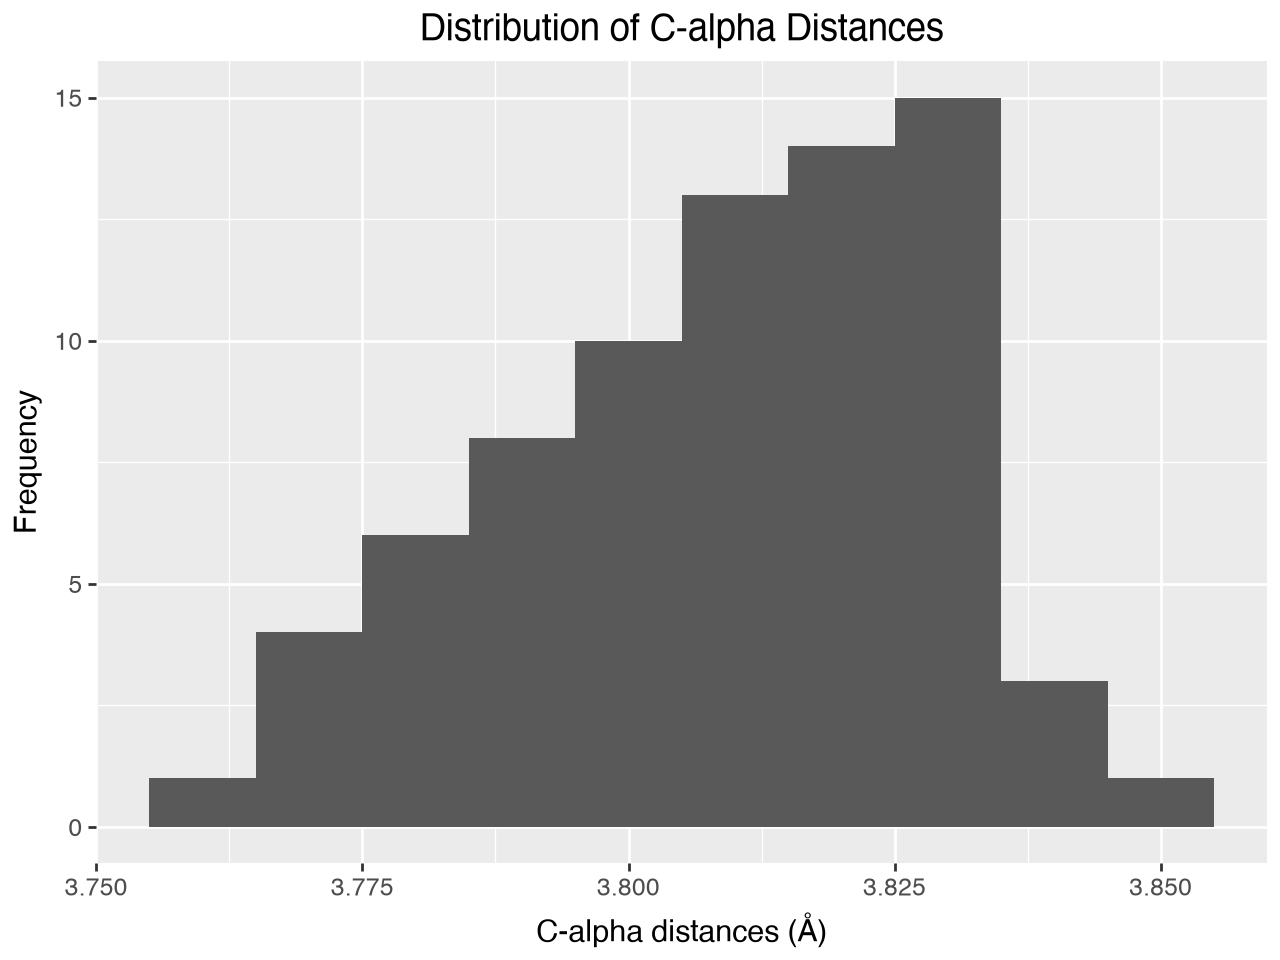

In [60]:
import numpy as np
import plotnine as pn

coordinates = df.loc[df["atom"].eq("CA"), ["x", "y", "z"]].to_numpy()

ca_distances = np.linalg.norm(np.diff(coordinates, axis=0), axis=1)
distances_df = pd.DataFrame({"ca_distances": ca_distances})

(
    pn.ggplot(distances_df, pn.aes(x="ca_distances"))
    + pn.geom_histogram(binwidth=0.01)
    + pn.labs(
        x="C-alpha distances (Å)",
        y="Frequency",
        title="Distribution of C-alpha Distances",
    )
)

Here we can see that indeed in our data, the distances between consecutive C-alpha atoms are heavily concentrated around 3.8 Å, as expected.

### 3D Visualization of C-alpha Atoms

To start to understand a small part of the protein structure, we can visualize the 3D coordinates of the C-alpha atoms. This helps us get an intuitive sense of the protein's backbone conformation.

We will use a simple 3D scatter plot to represent the positions of the C-alpha atoms in space.

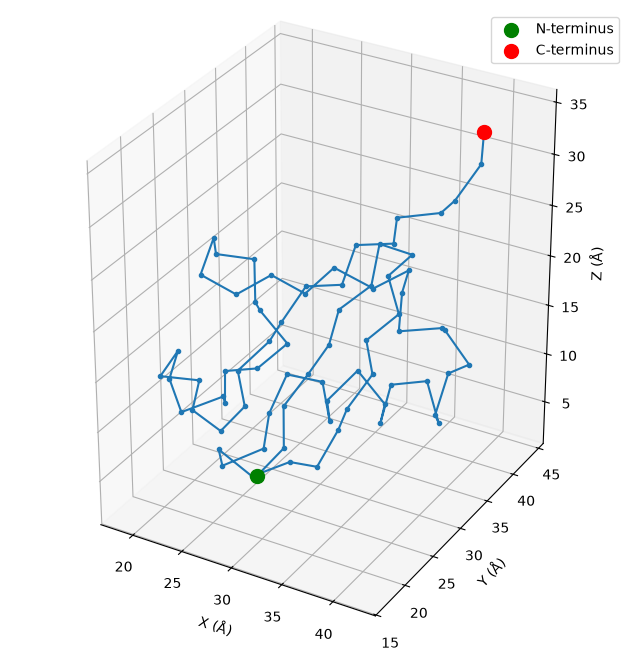

In [61]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.scatter(*coordinates[0], color="green", s=100, label="N-terminus")
ax.scatter(*coordinates[-1], color="red", s=100, label="C-terminus")

ax.legend()

ax.plot(
    coordinates[:, 0],
    coordinates[:, 1],
    coordinates[:, 2],
    marker="o",
    markersize=3,
)

ax.set_xlabel("X (Å)")
ax.set_ylabel("Y (Å)")
ax.set_zlabel("Z (Å)")

ax.set_box_aspect(np.ptp(coordinates, axis=0))
plt.show()

Here we can see a rough approximation of the 3d shape of the protein ubiquitin based on the positions of its C-alpha atoms. Here i have coloured the N-terminus in green and the C-terminus in red to highlight the directionality of the protein chain.